# DiaGraMo — Locked Temporal Study

Notebook chỉ đọc artifacts; không train, fit calibration, chọn threshold hoặc fusion weights.
Kết quả là exploratory internal CV, không phải external validation. Xem source-label confounding trước khi diễn giải hiệu năng.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
OUT=ROOT/'results/raw_temporal_v2/locked_study'
pd.set_option('display.max_columns',30)
pd.set_option('display.float_format',lambda x:f'{x:.6f}')
display(pd.DataFrame([json.loads((OUT/'status.json').read_text())]).drop(columns='inputs_sha256'))

,frozen_stroke_oof_complete,participants,folds,exploratory_internal_cv,external_validation,research_complete,new_training_or_calibration_in_report,new_experiment_launched,original_lite_primary_remains_duration,locked_research_direction
0,True,258,6,True,False,False,False,False,True,Multi-scale Relative Stroke Transformer + Kine...


## Kết quả cuối cùng trên đúng participant-matched OOF

In [2]:
display(pd.read_csv(OUT/'matched_oof_metrics.csv'))

,model,n,folds,accuracy,f1_macro,auc,balanced_accuracy,sensitivity,specificity,brier,log_loss,ece10
0,Kinematic,258,6,0.848837,0.847163,0.906902,0.847461,0.860140,0.834783,0.122450,0.406506,0.086405
1,Temporal,258,6,0.713178,0.713178,0.807540,0.721678,0.643357,0.800000,0.224193,0.752517,0.181813
2,Fixed50,258,6,0.841085,0.840681,0.906111,0.845576,0.804196,0.886957,0.129793,0.416361,0.079382


In [3]:
display(pd.read_csv(OUT/'matched_fold_metrics.csv')); display(pd.read_csv(OUT/'fold_mean_sd.csv'))

,model,fold,n,accuracy,f1_macro,auc,balanced_accuracy,sensitivity,specificity,brier,log_loss
0,Kinematic,0,43,0.837209,0.836856,0.895652,0.838043,0.826087,0.850000,0.132145,0.403166
1,Kinematic,1,43,0.860465,0.858553,0.960526,0.858553,0.875000,0.842105,0.080807,0.242239
2,Kinematic,2,43,0.837209,0.835788,0.901316,0.837719,0.833333,0.842105,0.130283,0.423278
3,Kinematic,3,43,0.906977,0.905702,0.899123,0.905702,0.916667,0.894737,0.112100,0.448556
4,Kinematic,4,43,0.813953,0.811404,0.864035,0.811404,0.833333,0.789474,0.154818,0.531165
5,Kinematic,5,43,0.837209,0.833977,0.903509,0.832237,0.875000,0.789474,0.124547,0.390629
6,Temporal,0,43,0.790698,0.790698,0.860870,0.794565,0.739130,0.850000,0.157195,0.582479
7,Temporal,1,43,0.790698,0.783193,0.914474,0.779605,0.875000,0.684211,0.140714,0.412226
8,Temporal,2,43,0.581395,0.581169,0.756579,0.592105,0.500000,0.684211,0.282189,0.883172
9,Temporal,3,43,0.720930,0.720779,0.807018,0.733553,0.625000,0.842105,0.257288,1.014902


,model,accuracy_mean,accuracy_std,f1_macro_mean,f1_macro_std,auc_mean,auc_std,balanced_accuracy_mean,balanced_accuracy_std,sensitivity_mean,sensitivity_std,specificity_mean,specificity_std,brier_mean,brier_std,log_loss_mean,log_loss_std
0,Fixed50,0.841085,0.074152,0.840433,0.073555,0.907625,0.046201,0.845746,0.066945,0.804650,0.132959,0.886842,0.039910,0.129793,0.031712,0.416361,0.097214
1,Kinematic,0.848837,0.032056,0.847047,0.032387,0.904027,0.031284,0.847276,0.032343,0.859903,0.035308,0.834649,0.040097,0.122450,0.024693,0.406506,0.094696
2,Temporal,0.713178,0.078750,0.711096,0.077840,0.828054,0.053877,0.721792,0.072567,0.644022,0.144641,0.799561,0.091470,0.224193,0.059687,0.752517,0.220113


## Complementarity và bất định — không phải bằng chứng nhân quả

In [4]:
display(pd.read_csv(OUT/'fusion_effect_by_fold.csv')); display(pd.read_csv(OUT/'branch_error_overlap.csv')); display(pd.read_csv(OUT/'paired_bootstrap.csv'))

,fold,corrected,harmed,unchanged_correct,unchanged_wrong,net_corrected
0,0,5,3,33,2,2
1,1,4,1,36,2,3
2,2,4,7,29,3,-3
3,3,1,7,32,3,-6
4,4,3,4,31,5,-1
5,5,3,0,36,4,3


,both_correct,kinematic_only,temporal_only,both_wrong,probability_correlation
0,159,60,25,14,0.503027


,model,reference,metric,delta,lower95,upper95,replicates,unit,stratified_by_label,fitted_models_fixed
0,Temporal,Kinematic,accuracy,-0.135659,-0.197674,-0.069767,2000,participant,True,True
1,Temporal,Kinematic,f1_macro,-0.133985,-0.197205,-0.068733,2000,participant,True,True
2,Temporal,Kinematic,auc,-0.099362,-0.152464,-0.045970,2000,participant,True,True
3,Temporal,Kinematic,balanced_accuracy,-0.125783,-0.186962,-0.060383,2000,participant,True,True
4,Temporal,Kinematic,sensitivity,-0.216783,-0.307692,-0.125874,2000,participant,True,True
5,Temporal,Kinematic,specificity,-0.034783,-0.130435,0.060870,2000,participant,True,True
6,Temporal,Kinematic,brier,0.101743,0.058758,0.142857,2000,participant,True,True
7,Temporal,Kinematic,log_loss,0.346012,0.201336,0.487984,2000,participant,True,True
8,Fixed50,Kinematic,accuracy,-0.007752,-0.054264,0.038760,2000,participant,True,True
9,Fixed50,Kinematic,f1_macro,-0.006483,-0.053470,0.041286,2000,participant,True,True


In [5]:
display(pd.read_csv(OUT/'participant_complementarity.csv').head(20))

,participant_id,label,fold,model,seed,logit,probability,prediction,checkpoint_sha256,kinematic_probability,fixed_average_probability,error_category,raw_minus_kinematic_probability,kinematic_correct,temporal_correct,fusion_correct,fusion_effect,probability_change
0,BR10301,0,4,stroke_transformer,42,-0.398919,0.401572,0,d3f4b2b988ce3121b9355dc9f9da9826a0cf60fb30ab17...,0.249635,0.325604,both_correct,0.151937,True,True,True,unchanged_correct,0.075968
1,BR10302,0,0,stroke_transformer,42,-2.532527,0.073609,0,f98df36aab6ea1b896c5c0ea9375fb0bb0ac70e952db17...,0.046320,0.059964,both_correct,0.027290,True,True,True,unchanged_correct,0.013645
2,BR10304,0,2,stroke_transformer,42,-4.260325,0.013921,0,47e4de69d1cffdf23cdbb9d8ec207bd769d88e35d03581...,0.008734,0.011327,both_correct,0.005187,True,True,True,unchanged_correct,0.002594
3,BR10305,0,3,stroke_transformer,42,-3.120284,0.042278,0,3c4b0e2518a7cfa00d544447fc65815c122e6b432567c0...,0.138935,0.090607,both_correct,-0.096657,True,True,True,unchanged_correct,-0.048329
4,BR10306,1,5,stroke_transformer,42,-2.650515,0.065957,0,d5abd2dd7b7bd670adbf0817dff60578380c01b91ced8a...,0.996677,0.531317,kin_only,-0.930720,True,False,True,unchanged_correct,-0.465360
5,BR10403,0,0,stroke_transformer,42,-5.329443,0.004823,0,f98df36aab6ea1b896c5c0ea9375fb0bb0ac70e952db17...,0.025581,0.015202,both_correct,-0.020757,True,True,True,unchanged_correct,-0.010379
6,BR10404,0,2,stroke_transformer,42,-3.679089,0.024624,0,47e4de69d1cffdf23cdbb9d8ec207bd769d88e35d03581...,0.008390,0.016507,both_correct,0.016234,True,True,True,unchanged_correct,0.008117
7,BR10405,0,3,stroke_transformer,42,1.488045,0.815785,1,3c4b0e2518a7cfa00d544447fc65815c122e6b432567c0...,0.376719,0.596252,kin_only,0.439065,True,False,False,harmed,0.219533
8,BR10406,1,0,stroke_transformer,42,-1.975084,0.121844,0,f98df36aab6ea1b896c5c0ea9375fb0bb0ac70e952db17...,0.991508,0.556676,kin_only,-0.869665,True,False,True,unchanged_correct,-0.434832
9,BR2401,0,3,stroke_transformer,42,-4.858091,0.007705,0,3c4b0e2518a7cfa00d544447fc65815c122e6b432567c0...,0.028684,0.018195,both_correct,-0.020978,True,True,True,unchanged_correct,-0.010489


## Data validity — nguồn thu thập tương quan mạnh với group

In [6]:
display(pd.read_csv(OUT/'source_associations.csv')); display(pd.read_csv(OUT/'prefix_city_mapping.csv',keep_default_na=False)); display(pd.read_csv(OUT/'source_fold_overlap.csv'))

,field,participants,categories,mixed_label_categories,single_label_categories,descriptive_label_purity,cramers_v
0,alphabetic_prefix,258,15,1,14,0.972868,0.946827
1,prefix_first5,258,62,6,56,0.972868,0.958774
2,id_city,258,15,1,14,0.972868,0.946827
3,id_school_ppp,258,35,4,31,0.972868,0.957250
4,site_type_ppp,258,2,1,1,0.655039,0.461384
5,date_of_administration,258,7,6,1,0.825581,0.671403


,prefix,n,cities,city_count,sites,group0,group1
0,BR,122,city1,1,11,115,7
1,CH,2,city2,1,1,0,2
2,DK,8,city3,1,1,0,8
3,HK,47,city4,1,9,0,47
4,JI,8,city5,1,1,0,8
5,JN,4,city6,1,1,0,4
6,MB,12,city7,1,2,0,12
7,ME,2,city8,1,1,0,2
8,NA,8,city9,1,2,0,8
9,NB,5,city10,1,1,0,5


,fold,field,test_participants,test_with_category_already_in_train,test_missing
0,0,alphabetic_prefix,43,43,0
1,0,id_city,43,43,0
2,0,id_school_ppp,43,43,0
3,0,date_of_administration,43,42,1
4,1,alphabetic_prefix,43,43,0
5,1,id_city,43,43,0
6,1,id_school_ppp,43,43,0
7,1,date_of_administration,43,42,1
8,2,alphabetic_prefix,43,43,0
9,2,id_city,43,43,0


In [7]:
display(pd.read_csv(OUT/'descriptive_metrics_by_city.csv'))

,city,model,n,group0,group1,accuracy,brier,auc
0,city1,Kinematic,122,115,7,0.836066,0.133538,0.894410
1,city1,Temporal,122,115,7,0.770492,0.170278,0.614907
2,city1,Fixed50,122,115,7,0.868852,0.113359,0.842236
3,city10,Kinematic,5,0,5,1.000000,0.079204,NaN
4,city10,Temporal,5,0,5,0.800000,0.197209,NaN
5,city10,Fixed50,5,0,5,0.800000,0.113350,NaN
6,city11,Kinematic,10,0,10,1.000000,0.030006,NaN
7,city11,Temporal,10,0,10,0.800000,0.219846,NaN
8,city11,Fixed50,10,0,10,0.900000,0.088296,NaN
9,city12,Kinematic,7,0,7,0.714286,0.172570,NaN


## Calibration diagnostics — không fit calibration trên OOF

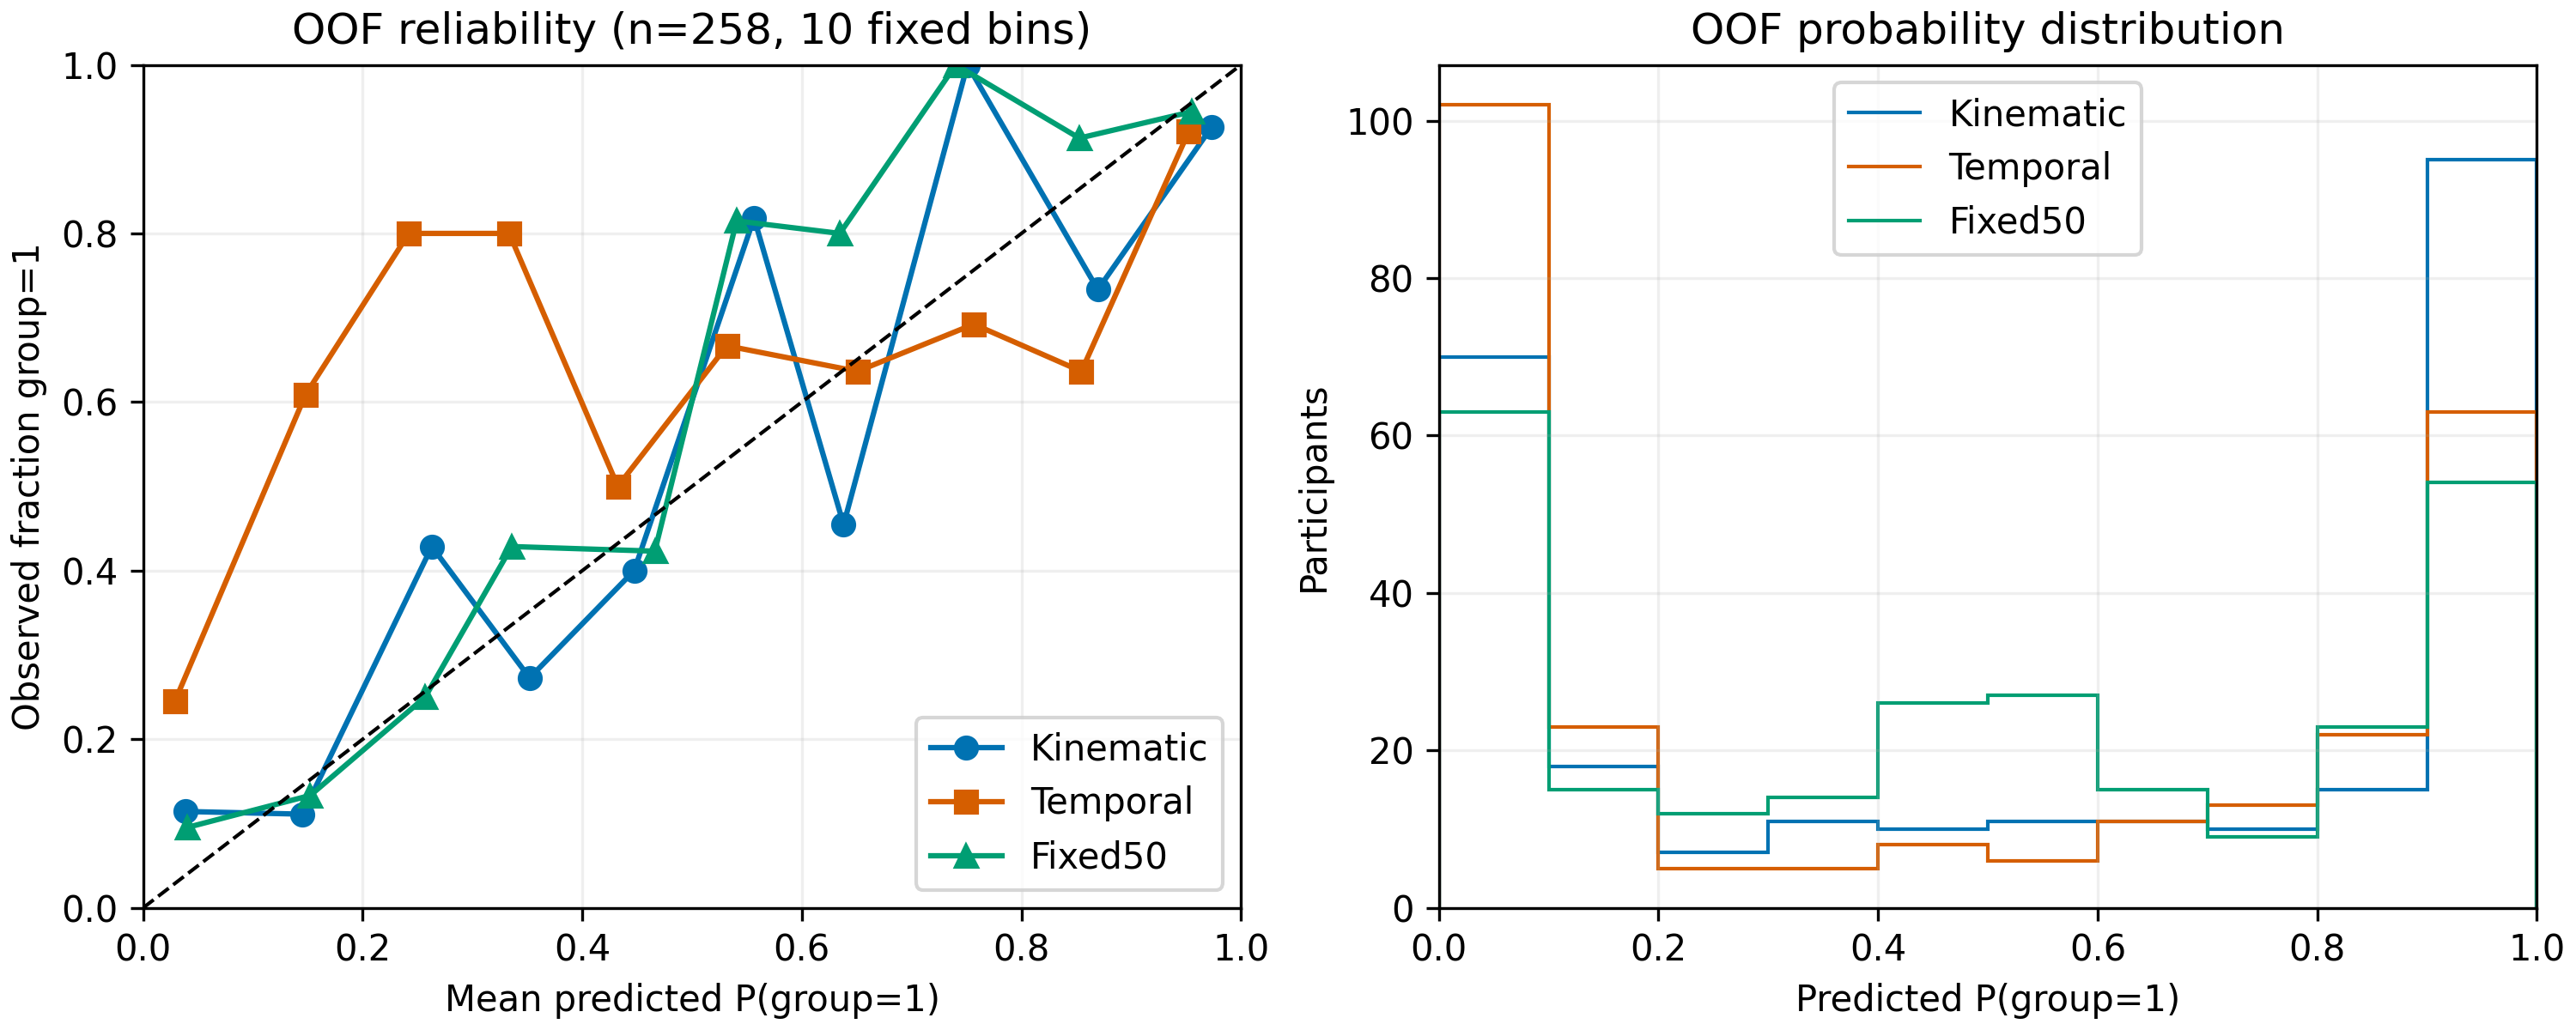

,model,bin,left,right,n,mean_probability,observed_rate,absolute_gap
0,Kinematic,0,0.000000,0.100000,70,0.038841,0.114286,0.075445
1,Kinematic,1,0.100000,0.200000,18,0.145125,0.111111,0.034014
2,Kinematic,2,0.200000,0.300000,7,0.262945,0.428571,0.165626
3,Kinematic,3,0.300000,0.400000,11,0.351985,0.272727,0.079258
4,Kinematic,4,0.400000,0.500000,10,0.447242,0.400000,0.047242
5,Kinematic,5,0.500000,0.600000,11,0.556435,0.818182,0.261747
6,Kinematic,6,0.600000,0.700000,11,0.637994,0.454545,0.183449
7,Kinematic,7,0.700000,0.800000,10,0.750809,1.000000,0.249191
8,Kinematic,8,0.800000,0.900000,15,0.869564,0.733333,0.136231
9,Kinematic,9,0.900000,1.000000,95,0.973293,0.926316,0.046978


In [8]:
display(Image(filename=str(OUT/'calibration.png'))); display(pd.read_csv(OUT/'calibration_bins.csv'))

## Ablation lịch sử: development, không phải six-fold OOF

In [9]:
display(pd.read_csv(OUT/'historical_ablation_evidence.csv'))

,experiment,seed,design,relative_time,relative_spatial,local_encoder,parameters,training_seconds,best_epoch,accuracy,f1_macro,auc,pr_auc,balanced_accuracy,sensitivity,specificity,brier,source,source_sha256,scope
0,p2_index_only_seed42,42,stroke_transformer,True,True,multiscale,25252,783.632473,5,0.569444,0.436221,0.496875,0.552552,0.521875,0.950000,0.093750,0.243679,results/raw_temporal_v2/phase2_temporal/p2_ind...,5824c5c2fd69378abd2b957145789d814b842c944c8719...,"Historical development, not six-fold OOF"
1,p2_mil_seed42,42,mil,True,True,multiscale,16626,1034.370044,5,0.569444,0.390663,0.431250,0.497698,0.515625,1.000000,0.031250,0.247237,results/raw_temporal_v2/phase2_temporal/p2_mil...,5922572cb117256ba3a191d1b4512affb76631eb48cffe...,"Historical development, not six-fold OOF"
2,p2_mil_seed43,43,mil,True,True,multiscale,16626,1187.233819,1,0.569444,0.390663,0.408594,0.478518,0.515625,1.000000,0.031250,0.249007,results/raw_temporal_v2/phase2_temporal/p2_mil...,c538eb907cc414b718c6dde05f3e0d9186750abad28dad...,"Historical development, not six-fold OOF"
3,p2_no_relative_spatial_seed42,42,stroke_transformer,True,False,multiscale,25252,1692.696141,33,0.777778,0.773407,0.848437,0.841901,0.771875,0.825000,0.718750,0.169418,results/raw_temporal_v2/phase2_temporal/p2_no_...,6dadc5ea3f6c19e5430f5ca7379e1b2f567c1e9382a139...,"Historical development, not six-fold OOF"
4,p2_no_relative_time_and_space_seed42,42,stroke_transformer,False,False,multiscale,25252,1657.207485,31,0.791667,0.788360,0.814844,0.838513,0.787500,0.825000,0.750000,0.175385,results/raw_temporal_v2/phase2_temporal/p2_no_...,691e65e8b2f93e3de5b233571644f6be34d40ea2aa202c...,"Historical development, not six-fold OOF"
5,p2_no_relative_time_seed42,42,stroke_transformer,False,True,multiscale,25252,1031.802623,17,0.625000,0.582385,0.639063,0.716761,0.596875,0.850000,0.343750,0.228740,results/raw_temporal_v2/phase2_temporal/p2_no_...,401ec048005e16e424f3beaab24e0ccaa8dc09cfbb57de...,"Historical development, not six-fold OOF"
6,p2_original_encoder_mil_seed42,42,mil,True,True,original,4018,432.454272,1,0.569444,0.390663,0.449219,0.508054,0.515625,1.000000,0.031250,0.251248,results/raw_temporal_v2/phase2_temporal/p2_ori...,002da0677a10d9b22c5b44b290ea4ab672199f9cc4500b...,"Historical development, not six-fold OOF"
7,p2_p1_reference_seed43,43,hierarchical,NaN,NaN,NaN,29810,274.264487,27,0.819444,0.808784,0.924219,0.939750,0.803125,0.950000,0.656250,0.138005,results/raw_temporal_v2/phase2_temporal/p2_p1_...,78e6fb372c71f25659384aa2196bae04ee26c52def19bd...,"Historical development, not six-fold OOF"
8,p2_statistical_seed42,42,statistical,True,True,multiscale,19730,919.096932,12,0.569444,0.559155,0.617969,0.620142,0.559375,0.650000,0.468750,0.236928,results/raw_temporal_v2/phase2_temporal/p2_sta...,7cbf1fc2f82042b1e43b58bc188a9361147c11484ceaab...,"Historical development, not six-fold OOF"
9,p2_statistical_seed43,43,statistical,True,True,multiscale,19730,1356.376169,22,0.680556,0.680494,0.753125,0.798342,0.687500,0.625000,0.750000,0.209184,results/raw_temporal_v2/phase2_temporal/p2_sta...,cb3e4eca5af4506ce9172b8c586ee19fbf851929e2102e...,"Historical development, not six-fold OOF"


In [10]:
display(Markdown((OUT/'LOCKED_RESEARCH_REPORT_VI.md').read_text(encoding='utf-8')))

# DiaGraMo — Báo cáo nghiên cứu theo đặc tả khóa

Trạng thái: **Hoàn tất sáu folds của đánh giá Stroke Transformer cố định**, 258 người, 6/6 folds. Đây là **exploratory internal CV**, không phải external validation hay bằng chứng lâm sàng. Nghiên cứu tổng thể vẫn chưa hoàn tất. Không triển khai thí nghiệm tiếp theo trong báo cáo này.

**Kết quả chính:** Kinematic F1=0.847163, Temporal F1=0.713178, Fixed50 F1=0.840681. Fixed50−Kinematic=-0.006483, CI95% [-0.053470,+0.041286]. Point estimate fusion thấp hơn baseline, không có bằng chứng cải thiện tổng thể. Tín hiệu tích cực ở hai folds đầu không được duy trì trong kết quả toàn bộ sáu folds.

## 1. Kiến trúc thực sự được triển khai

Nhánh Kinematic gồm 14 tác vụ × 74 đặc trưng = 1.036, LightGBM được bảo vệ, xuất pK. Nhánh Temporal xuất pT, sử dụng tín hiệu online gốc SVC và 21 kênh tiền xử lý. Window không chồng lấp, tối đa 128 mẫu và không vượt ranh giới pen-state/timestamp. Segment là đơn vị tính toán từ các ranh giới đó, **không phải nét viết được chuyên gia gán nhãn lâm sàng**.

```mermaid
flowchart LR
    S[SVC gốc] --> P[21 kênh; windows tối đa 128 mẫu]
    P --> C[CNN kernel 5/13/29; 4 token/window]
    C --> G[Learned pooling thành segment]
    G --> A[Relative attention 2 heads; tối đa 32 segment/nhóm]
    A --> T[Task identity và learned pooling]
    T --> PT[pT]
    K[1036 Kinematic features] --> L[Protected LightGBM]
    L --> PK[pK]
    PT --> F[Trung bình cố định 50/50]
    PK --> F
```

`MultiScaleLocal` có ba Conv1d 21→8, kernel 5/13/29, stride 4; nối 24 kênh, Conv1d 1×1→32; hai residual convolution kernel 3 với dilation 2/4. GELU; giữ bốn token 32 chiều/window bằng masked mean trên bốn vùng feature map. Learned pooling gom tối đa 64 token (16 window) mỗi chunk segment; weighted scatter-average theo số token hợp lệ gom chunk về segment. Relative attention **hai heads** chỉ chạy trong nhóm tối đa **32 segment** của cùng tác vụ, không trên toàn bộ chuỗi mẫu gốc.

Relative bias: signed-log chênh lệch thời gian, positive gap, duration ratio, displacement centroid x/y, khác biệt tỷ lệ pen-down và self-identity; MLP 7→8→2. Spatial dùng device units, centroid xấp xỉ từ cache; không phải khoảng cách sinh cơ học đã hiệu chuẩn. Attention có residual, LayerNorm và FFN 32→64→32. Learned pooling gom segment chunks thành task, thêm task identity embedding, LayerNorm/Linear/GELU/dropout, rồi **learned pooling trên 14 task**, LayerNorm và linear head. **Không có task-level Transformer** và không dùng duration-weighted participant pooling của `RecoveryModel`. Tổng tham số Temporal: 25.252.

Fusion khóa: **pF = 0,5 pK + 0,5 pT**, không tham số học. Threshold giữ nguyên code `p > 0.5`. Seed42, 28 epochs cuối cùng, AdamW lr0,001/weight decay0,001, dropout0,1, dim32, effective batch8/microbatch2, gradient clip1. Không early stopping, calibration, threshold tuning hoặc chọn lại checkpoint theo outer Test. Config lite lịch sử vẫn đánh dấu Duration là primary tại thời điểm khóa ban đầu; hướng nghiên cứu mới ưu tiên Stroke theo yêu cầu người dùng sau khi đã xem partial scores. Sự thay đổi trọng tâm này không được gọi là lựa chọn độc lập với cohort.

Nguồn triển khai: [multiscale.py](../../../src/diagramo/temporal_v2/multiscale.py), [dataset.py](../../../src/diagramo/temporal/dataset.py), [frozen trainer](../../../scripts/run_raw_temporal_v2_phase4_lite.py) và [config](../../../configs/raw_temporal_v2/phase4_lite.json).

## 2. Dataset và tiền xử lý

258 participants, nhãn `group` (115 lớp0/143 lớp1), 14 tasks đầy đủ; `group` là phân nhóm của dataset, không đồng nhất với chẩn đoán dysgraphia riêng. Giữ đúng assignments Stratified6/shuffle/seed42; mỗi outer Train215/Test43, participant không giao nhau. Normalizer fit riêng 215 Train và kiểm tra từ checkpoint; ID chỉ tra cứu recording và chia fold, không phải biến đầu vào. Task ID là danh tính tác vụ, khác participant ID.

Selection lịch sử trong `prepare.py` yêu cầu đủ14 tasks, không trùng task, tín hiệu hợp lệ/hữu hạn và group∈{0,1}; **không dùng `flag_to_omit_total` làm điều kiện loại**. Cohort cố định hiện có3 người flag=1, vẫn được giữ để không đổi protocol/baseline. Đây là hạn chế cần xác minh với chủ dữ liệu, không tự loại người sau khi xem OOF. Chẩn đoán riêng có140 người diagnosis1/118 diagnosis0, khác số lượng group.

| flag_to_omit_total | group0 | group1 |
| --- | --- | --- |
| 0 | 113 | 142 |
| 1 | 2 | 1 |

| group | diagnosis0 | diagnosis1 |
| --- | --- | --- |
| 0 | 114 | 1 |
| 1 | 4 | 139 |

21 kênh: relative_x/y, pressure, azimuth, tilt, elapsed_time, delta_time, pen_down, vx/vy/speed, ax/ay, velocity_valid, acceleration_valid, dt_valid, duplicate_time, negative_time, tiny_interval, large_gap, boundary. Ngưỡng dt hợp lệ [1e-4,1] theo code/đơn vị nguồn; đạo hàm chỉ qua các mẫu pen-down cùng trạng thái và dt hợp lệ. Không sort hoặc xóa mẫu để che timestamp lỗi. Signed-log cho kênh liên tục, Train normalization và clip [-10,10]. Dữ liệu RAM float16 là tối ưu lưu trữ, math/gradients float32; inventory thời gian/index được giữ. Cache hiện tại được tạo lại từ SVC gốc sau audit lịch sử; không nhầm audit merged export cũ với cache đang sử dụng. Xem Phase0 source audit và source migration có SHA để truy nguyên khác biệt export.

## 3. OOF và đối chiếu participant-matched

| model | n | folds | accuracy | f1_macro | auc | balanced_accuracy | sensitivity | specificity | brier | log_loss | ece10 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Kinematic | 258 | 6 | 0.848837 | 0.847163 | 0.906902 | 0.847461 | 0.860140 | 0.834783 | 0.122450 | 0.406506 | 0.086405 |
| Temporal | 258 | 6 | 0.713178 | 0.713178 | 0.807540 | 0.721678 | 0.643357 | 0.800000 | 0.224193 | 0.752517 | 0.181813 |
| Fixed50 | 258 | 6 | 0.841085 | 0.840681 | 0.906111 | 0.845576 | 0.804196 | 0.886957 | 0.129793 | 0.416361 | 0.079382 |

Mean ± sample SD từng fold có trong `fold_mean_sd.csv`; AUC trên pooled OOF không bằng trung bình AUC fold. Các metrics ở đây chỉ dùng đúng các participant đã có OOF Temporal. Không so partial Temporal với baseline toàn cohort.

| model | fold | n | accuracy | f1_macro | auc | balanced_accuracy | sensitivity | specificity | brier | log_loss |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| Kinematic | 0 | 43 | 0.837209 | 0.836856 | 0.895652 | 0.838043 | 0.826087 | 0.850000 | 0.132145 | 0.403166 |
| Kinematic | 1 | 43 | 0.860465 | 0.858553 | 0.960526 | 0.858553 | 0.875000 | 0.842105 | 0.080807 | 0.242239 |
| Kinematic | 2 | 43 | 0.837209 | 0.835788 | 0.901316 | 0.837719 | 0.833333 | 0.842105 | 0.130283 | 0.423278 |
| Kinematic | 3 | 43 | 0.906977 | 0.905702 | 0.899123 | 0.905702 | 0.916667 | 0.894737 | 0.112100 | 0.448556 |
| Kinematic | 4 | 43 | 0.813953 | 0.811404 | 0.864035 | 0.811404 | 0.833333 | 0.789474 | 0.154818 | 0.531165 |
| Kinematic | 5 | 43 | 0.837209 | 0.833977 | 0.903509 | 0.832237 | 0.875000 | 0.789474 | 0.124547 | 0.390629 |
| Temporal | 0 | 43 | 0.790698 | 0.790698 | 0.860870 | 0.794565 | 0.739130 | 0.850000 | 0.157195 | 0.582479 |
| Temporal | 1 | 43 | 0.790698 | 0.783193 | 0.914474 | 0.779605 | 0.875000 | 0.684211 | 0.140714 | 0.412226 |
| Temporal | 2 | 43 | 0.581395 | 0.581169 | 0.756579 | 0.592105 | 0.500000 | 0.684211 | 0.282189 | 0.883172 |
| Temporal | 3 | 43 | 0.720930 | 0.720779 | 0.807018 | 0.733553 | 0.625000 | 0.842105 | 0.257288 | 1.014902 |
| Temporal | 4 | 43 | 0.720930 | 0.720779 | 0.809211 | 0.733553 | 0.625000 | 0.842105 | 0.245736 | 0.762463 |
| Temporal | 5 | 43 | 0.674419 | 0.669956 | 0.820175 | 0.697368 | 0.500000 | 0.894737 | 0.262038 | 0.859862 |
| Fixed50 | 0 | 43 | 0.883721 | 0.883469 | 0.934783 | 0.884783 | 0.869565 | 0.900000 | 0.106915 | 0.336639 |
| Fixed50 | 1 | 43 | 0.930233 | 0.927731 | 0.982456 | 0.921053 | 1.000000 | 0.842105 | 0.076115 | 0.260926 |
| Fixed50 | 2 | 43 | 0.767442 | 0.767316 | 0.903509 | 0.780702 | 0.666667 | 0.894737 | 0.143810 | 0.429307 |
| Fixed50 | 3 | 43 | 0.767442 | 0.767316 | 0.868421 | 0.780702 | 0.666667 | 0.894737 | 0.145981 | 0.492690 |
| Fixed50 | 4 | 43 | 0.790698 | 0.790244 | 0.855263 | 0.796053 | 0.750000 | 0.842105 | 0.159707 | 0.496448 |
| Fixed50 | 5 | 43 | 0.906977 | 0.906522 | 0.901316 | 0.911184 | 0.875000 | 0.947368 | 0.146229 | 0.482158 |

## 4. Complementarity và mức bất định

| both_correct | kinematic_only | temporal_only | both_wrong | probability_correlation |
| --- | --- | --- | --- | --- |
| 159 | 60 | 25 | 14 | 0.503027 |

Fusion corrected/harmed được tính bằng so sánh nhãn dự đoán pF với pK, không phải chỉ việc xác suất tăng/giảm. Chi tiết từng participant gồm pK/pT/pF và thay đổi xác suất nằm trong `participant_complementarity.csv`.

| fold | corrected | harmed | unchanged_correct | unchanged_wrong | net_corrected |
| --- | --- | --- | --- | --- | --- |
| 0 | 5 | 3 | 33 | 2 | 2 |
| 1 | 4 | 1 | 36 | 2 | 3 |
| 2 | 4 | 7 | 29 | 3 | -3 |
| 3 | 1 | 7 | 32 | 3 | -6 |
| 4 | 3 | 4 | 31 | 5 | -1 |
| 5 | 3 | 0 | 36 | 4 | 3 |

Chênh lệch Fixed50−Kinematic theo fold (Brier/log-loss âm là tốt hơn):

| fold | accuracy | f1_macro | auc | balanced_accuracy | sensitivity | specificity | brier | log_loss |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 0 | 0.046512 | 0.046612 | 0.039130 | 0.046739 | 0.043478 | 0.050000 | -0.025230 | -0.066527 |
| 1 | 0.069767 | 0.069178 | 0.021930 | 0.062500 | 0.125000 | 0.000000 | -0.004692 | 0.018687 |
| 2 | -0.069767 | -0.068472 | 0.002193 | -0.057018 | -0.166667 | 0.052632 | 0.013527 | 0.006030 |
| 3 | -0.139535 | -0.138386 | -0.030702 | -0.125000 | -0.250000 | 0.000000 | 0.033882 | 0.044134 |
| 4 | -0.023256 | -0.021160 | -0.008772 | -0.015351 | -0.083333 | 0.052632 | 0.004889 | -0.034717 |
| 5 | 0.069767 | 0.072545 | -0.002193 | 0.078947 | 0.000000 | 0.157895 | 0.021682 | 0.091529 |

F1 tăng ở 3/6 folds, giảm ở 3, bằng ở 0. Tính nhất quán phải xét cùng cỡ mẫu43/fold, không chỉ point estimate pooled.

| metric | delta | lower95 | upper95 |
| --- | --- | --- | --- |
| accuracy | -0.007752 | -0.054264 | 0.038760 |
| f1_macro | -0.006483 | -0.053470 | 0.041286 |
| auc | -0.000791 | -0.026575 | 0.027124 |
| balanced_accuracy | -0.001885 | -0.049802 | 0.046795 |
| sensitivity | -0.055944 | -0.118881 | 0.006993 |
| specificity | 0.052174 | -0.026087 | 0.130435 |
| brier | 0.007343 | -0.012722 | 0.026393 |
| log_loss | 0.009856 | -0.057315 | 0.070234 |

Bootstrap paired 2.000 lần, seed42, lấy lại mẫu participant trong từng lớp (cố định tỷ lệ lớp), cùng chỉ số cho cả ba mô hình; percentile95%. Giữ nguyên mô hình đã fit, không tái huấn luyện bootstrap. CI không bao gồm toàn bộ bất định do training/model selection, phụ thuộc do Train folds chồng lấp hoặc confounding nguồn; không sửa được historical researcher selection bias. Không chọn tham số hay thay rule dựa trên CI này.

## 5. Calibration

Brier/log-loss/ECE10 và reliability plot là **diagnostics** từ OOF, không dùng để hiệu chỉnh xác suất. ECE phụ thuộc binning, chỉ 258 người nên các bin ít mẫu có thể không ổn định; empty bins được giữ trong CSV và không nối như dữ liệu quan sát. Fusion có thể giúp do làm dịu overconfidence hoặc calibration, không tự động chứng minh Temporal học thêm cấu trúc vận động. Chưa có train-only calibrated Kinematic control trong thí nghiệm cố định, vì thêm nó sau khi xem Test sẽ đổi protocol. Nếu làm nghiên cứu tiếp, calibration phải fit/cross-fit hoàn toàn trong outer Train và được khóa riêng.

Fixed50 thay đổi sensitivity -0.055944, specificity +0.052174, Brier +0.007343, log-loss +0.009856, ECE10 -0.007023. Đánh giá các thước đo cùng nhau; ECE giảm riêng lẻ không đủ khẳng định calibration tốt hơn nếu proper scoring rules xấu đi.

![Calibration và phân bố xác suất](calibration.png)

## 6. Data validity: prefix, nguồn thu thập và nhãn

Metadata được nối chính xác bằng ID với merged participant metadata và kiểm tra nhãn cả258 người. CSV cognitive gốc có 258 exact ID matches; group/city/site được đối chiếu giữa CSV gốc và merged metadata. Các biến nguồn chỉ dùng kiểm toán, **không huấn luyện predictor bằng ID/prefix/city/site/date**. Purity bên dưới là thống kê mô tả trên cohort, không phải accuracy cross-validation của một mô hình.

| field | participants | categories | mixed_label_categories | single_label_categories | descriptive_label_purity | cramers_v |
| --- | --- | --- | --- | --- | --- | --- |
| alphabetic_prefix | 258 | 15 | 1 | 14 | 0.972868 | 0.946827 |
| prefix_first5 | 258 | 62 | 6 | 56 | 0.972868 | 0.958774 |
| id_city | 258 | 15 | 1 | 14 | 0.972868 | 0.946827 |
| id_school_ppp | 258 | 35 | 4 | 31 | 0.972868 | 0.957250 |
| site_type_ppp | 258 | 2 | 1 | 1 | 0.655039 | 0.461384 |
| date_of_administration | 258 | 7 | 6 | 1 | 0.825581 | 0.671403 |

| prefix | n | cities | city_count | sites | group0 | group1 |
| --- | --- | --- | --- | --- | --- | --- |
| BR | 122 | city1 | 1 | 11 | 115 | 7 |
| CH | 2 | city2 | 1 | 1 | 0 | 2 |
| DK | 8 | city3 | 1 | 1 | 0 | 8 |
| HK | 47 | city4 | 1 | 9 | 0 | 47 |
| JI | 8 | city5 | 1 | 1 | 0 | 8 |
| JN | 4 | city6 | 1 | 1 | 0 | 4 |
| MB | 12 | city7 | 1 | 2 | 0 | 12 |
| ME | 2 | city8 | 1 | 1 | 0 | 2 |
| NA | 8 | city9 | 1 | 2 | 0 | 8 |
| NB | 5 | city10 | 1 | 1 | 0 | 5 |
| RK | 10 | city11 | 1 | 1 | 0 | 10 |
| SO | 7 | city12 | 1 | 1 | 0 | 7 |
| TL | 7 | city13 | 1 | 1 | 0 | 7 |
| TU | 8 | city14 | 1 | 1 | 0 | 8 |
| VV | 8 | city15 | 1 | 1 | 0 | 8 |

Trong cohort đầy đủ, BR/city1 có 115 lớp0 và7 lớp1; 14 thành phố còn lại có136 người, đều lớp1. Prefix→city là ánh xạ một-một trên cohort. Cramér V≈0,947 cho city–group, và label purity mô tả≈97,29%: **source-label confounding rất mạnh**. Không suy ra city gây khác biệt chữ viết, cũng không suy ra lỗi gán nhãn. Không thể dùng thành tích CV ngẫu nhiên hiện tại để tách bệnh lý khỏi nguồn. `descriptive_metrics_by_city.csv` chỉ là kiểm tra hậu nghiệm theo nguồn, không phải một validation/site-held-out mới; city1 chỉ có7 người lớp1 nên bất định lớn, các city chỉ một lớp không có AUC hợp lệ.

Các bảng `source_label_contingencies.csv` và `source_fold_overlap.csv` cho thấy phân bố group theo prefix, city, school/site và kỳ thu thập, cũng như nguồn xuất hiện đồng thời trong Train/Test. `id_school_ppp` là trường/điểm theo tên metadata, không tự đồng nhất với hardware hoặc bệnh viện tuyển mẫu. `date_of_administration` là kỳ thu thập, không có bằng chứng đây là batch phần cứng. Các trường phần cứng/batch/tuyển mẫu được tìm thấy: []. Không có metadata phù hợp thì nguyên nhân chính xác vẫn **chưa xác định**, không được quy kết hardware/site bằng suy đoán. Missing counts: {'id_city': 0, 'id_school_ppp': 0, 'site_type_ppp': 0, 'date_of_administration': 3}.

**Ba vấn đề khác nhau:** (i) confounding nguồn: tín hiệu có thể chứa khác biệt site/thiết bị/tuyển mẫu tương quan group dù ID không vào network; (ii) direct leakage: ID, group hoặc Test labels bị đưa vào input/fitting; kiểm tra pipeline hiện tại không phát hiện đường vào này, nhưng không chứng minh hết mọi confounding; (iii) researcher-level selection bias: cohort đã dùng trong nhiều quyết định nghiên cứu. Participant-independent fitting không làm các quyết định model selection trở thành validation độc lập. Nếu city/site gần như chỉ có một lớp, không thể tách ảnh hưởng nguồn và group bằng CV ngẫu nhiên; cần thiết kế thu thập hai lớp trong cùng nguồn và nguồn độc lập, không tự sửa assignments hiện tại.

## 7. Diễn giải ablation có đối chứng

`historical_ablation_evidence.csv` giữ lại 12 fits Phase2, SHA nguồn, số tham số, runtime và epoch chọn trên development. Đây là split143 Train/72 validation và chủ yếu một seed cho ablation, **không phải sáu-fold OOF**; không được gộp như sáu-fold bằng chứng. MIL và Stroke dùng cùng multi-scale local encoder/learned pooling, nhưng attention làm tăng capacity từ16.626 lên25.252 tham số; statistical có19.730, original-local MIL4.018. Vì vậy chênh lệch không tự cô lập tác dụng cấu trúc thời gian khỏi capacity/optimization.

Ở seed42 development, full relative F1≈0,7469; tắt relative time≈0,5824; tắt spatial≈0,7734; tắt cả time+spatial≈0,7884. Các kết quả không chứng minh mọi thành phần relative đều có lợi; time/space ở đây chỉ là relative bias, không xóa toàn bộ kênh thời gian/vị trí khỏi encoder. Training durations và số epoch khác nhau do development checkpoint selection; chưa có equal-budget/equal-capacity multi-seed ablation hoàn chỉnh.

Historical perturbation: transport cùng content và metadata gần như bất biến vì permutation equivariance của attention và pooling; đó không phải bằng chứng mô hình bỏ qua thời gian. Content-only reversal giữ metadata tại chỗ tạo mismatch và có thể out-of-distribution; thay đổi xác suất nhỏ không cho suy luận nhân quả hay chứng minh motor invariance. Rare-event/high-speed removal cũng thay phân bố input. Attention weights là trọng số tính toán, không phải causal explanation. Không chạy perturbation hoặc ablation mới sau khi xem frozen Test.

## 8. Quyết định C1/C2/C3

ΔF1 Fixed50−Kinematic hiện tại = -0.006483, CI95% [-0.053470,+0.041286]. Đủ sáu folds của protocol cố định để báo cáo toàn bộ; không tự khởi chạy nghiên cứu mới.

C1 vẫn là giả thuyết về structured temporal representation: đã triển khai cấu trúc và có development controls, nhưng chưa chứng minh đóng góp độc lập với capacity, pooling, optimization hoặc calibration. C2 chỉ có thể được mô tả ở mức kết quả complementary OOF nội bộ của frozen average; cần xem CI, corrected/harmed và tính nhất quán sáu folds, đồng thời đặt confounding nguồn lên trước F1. Ngay cả khi point estimate tăng, không gọi đây là incremental motor evidence đã được xác nhận trên dữ liệu độc lập.

**Quyết định hiện tại:** chưa đầu tư full nested architecture/fusion search hoặc SSL trên cùng cohort để chạy theo F1. Ưu tiên xác minh nguồn tuyển mẫu, điều kiện thu thập/phần cứng và bổ sung dữ liệu có cả hai lớp trong cùng nguồn. C1 có thể theo đuổi như một nghiên cứu đối chứng riêng (equal-capacity/equal-budget, multi-seed, relative-time/spatial và order stress có thảo luận OOD), không coi development ablation hiện tại là kết luận đóng góp. C2 cần source-aware/independent validation và calibrated Kinematic control trước khi tuyên bố giá trị vận động bổ sung. Cả hai hướng chỉ được **đề xuất**, chưa khởi chạy.

Nếu tín hiệu cải thiện nhất quán và không bị nguồn dữ liệu giải thích, đề xuất nghiên cứu riêng có train-only calibrated Kinematic control, cross-fitted fusion và tập kiểm chứng độc lập; chưa chạy trong nhiệm vụ này. Nếu hiệu quả yếu/không nhất quán hoặc source-label confounding mạnh, ưu tiên xác minh recruitment/site/device và validation phù hợp thay vì tăng độ phức tạp. Không bắt đầu SSL, larger Transformer, architecture grid, selective fusion hoặc threshold tuning. C3 (cross-domain/language robustness và clinical biomarkers) là hướng tương lai **chưa được chứng minh**.

## 9. Bảo toàn và chi phí

Snapshot trước khi resume ở `history_9363d15/`; checkpoints thành công không huấn luyện lại. Cấu hình/chữ ký training vẫn giữ nguyên; các aggregate outputs cập nhật được giữ cả bản snapshot. Runtime từng fit, phần dở và GPU allocated/reserved ở `../phase4_lite/runtime_memory.csv` và `incomplete_fit_runtime.csv`; session logs ghi giới hạn110 phút/một worker. Không cộng trùng thời gian fit và session, không gọi GPU tensor allocation là tổng process VRAM. Ảnh PNG300dpi/SVG và các bảng đi kèm phục vụ manuscript, chưa gắn chuẩn journal cụ thể. Không push/merge tự động.

Phiên mới nhất: 90.43 phút so với giới hạn 110 phút; includes_process_setup=False, includes_reporting=True. Thời gian startup trước SessionBudget không được tính như GPU training. Tổng chi phí training các Temporal folds đã hoàn tất (cộng dồn cả các phiên trước) là 139.76 phút; đây không phải thời gian của riêng phiên mới. Peak tensor allocated tối đa 289.27 MiB; reserved tối đa 940.00 MiB. `gpu_snapshot_20261121.csv` chỉ là snapshot NVML của phiên mới, không phải peak process memory liên tục.
